# Copia de consulta — no editar ni usar para entrenar

Original: `notebooks/10_deteccion_yolo26n.ipynb` · SHA-256 (UTF-8, saltos LF): `ba8322969e7190f579be5efa1753a7ea2edb06a7061a30befcbea4de68831db9`.

Tipo: **consulta_guardada**. Fecha de ejecución/consulta: 2026-11-10T03:26:29.217471+00:00. Commit de ejecución: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Entorno de ejecución: `{"Pillow": "12.1.1", "figure_dpi": 55, "matplotlib": "3.10.8", "nbclient": "0.10.4", "numpy": "1.26.4", "pandas": "2.2.2", "python": "3.11.9", "scikit-learn": "1.7.2", "sistema": "Windows-10-10.0.26200-SP0"}`. Publicación: 2026-11-10T00:36:00-03:00. Commit de referencia del código: `92f76cf1e05f11a43be6d79a29c6e515d17f2721`.

Preparación del insumo: sin celdas omitidas.

Celdas ejecutadas (índices del original): [11]. Familia del test: no aplica.

Una consulta de corridas guardadas muestra resultados reales ya existentes; no reproduce los logs del entrenamiento. Val eligió checkpoints y se usa para reportar. Se quitaron widgets y formatos activos; en test se quitaron todas las imágenes.


# 10. Detección con YOLO26n

Abrir en **Colab con GPU T4**, en una sesión nueva, y ejecutar de arriba hacia abajo.
Se usan las 900 imágenes existentes y el split oficial 738/162. No se agregan imágenes.
YOLO26n es la tercera versión de YOLO que la consigna da como opcional.

Se comparan dos corridas **independientes**, ambas desde pesos COCO `yolo26n.pt`:
entrenar toda la red y congelar el backbone (módulos 0–10). Se mantiene la
misma receta que `08_deteccion_yolov8n` y `09_deteccion_yolo11n`, incluido el tamaño de
entrada de **640 px** (las imágenes de 256 se agrandan). No es una comparación
controlada con las CNN de clasificación.

**Este notebook usa otro entorno:** `requirements-yolo26.txt` (Ultralytics 8.4.184), porque
la 8.3.221 del 08 y el 09 no incluye YOLO26. Así que frente a esos dos cambia la arquitectura
y también la versión de la librería. Los pesos guardados acá **no se abren con 8.3.221**: los
carga sin error, pero predice otras cajas.

Las etiquetas se preparan en una **copia local RGB**: clase única `panel` (0), excluir
solo Z01/línea 1, conservar cajas pequeñas y confianza original como metadatos.
N06/N16 conservan su referencia provisional. Los originales no se modifican.

**Val elige el checkpoint y también se usa para reportar**: no es un test independiente.
Se calculan mAP50/mAP50-95 y curvas PR sobre todo val y sobre Jamaica (23 imágenes).
Como clasificador se usa la máxima confianza de las cajas; no es probabilidad calibrada.
El umbral inicial 0.25 es exploratorio y no se optimiza aquí.

Drive: `Mi unidad/PDI-TP/resultados/yolo26n/<modo>/`, con `modelo.pt`, métricas,
predicciones, cajas y subcarpetas de entrenamiento/evaluación. Dejar espacio para ambas
corridas. Los checkpoints `best.pt` y `last.pt` se escriben en Drive en cada época;
si falla la sesión se recupera hasta la última época guardada.


In [ ]:
# 1. Opciones: comenzar con ambas variantes para cubrir la comparación de la consigna.
REPETIR = False  # True archiva la corrida anterior y vuelve a entrenar.
MODOS = {"coco_completo": 0, "coco_backbone_congelado": 11}
SEMILLA = 42
LADO = 640  # Las imágenes son de 256: Ultralytics las agranda. Igual que YOLOv8n y YOLO11n.
BATCH = 16
EPOCAS = 50
PACIENCIA = 10
UMBRAL = 0.25
CONF_MIN = 0.001  # Bajo para calcular PR/mAP; distinto del umbral de clasificación.
IOU_NMS = 0.7  # Solo vale con NMS: la cabeza sin NMS (nms=False) lo ignora.
MAX_DETECCIONES = 300
assert 0 < CONF_MIN < UMBRAL <= 1

In [ ]:
# 2. Código y dependencias: entorno propio: YOLO26 no está en la Ultralytics del 08 y el 09.
import importlib.util
import os
import subprocess
import sys
from pathlib import Path
if importlib.util.find_spec("google.colab") is None:
    raise RuntimeError("Abrir este notebook en Google Colab con GPU T4.")

repo = Path("/content/PDI-TP")
if repo.is_dir():
    subprocess.run(["git", "-C", str(repo), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/candeperles/PDI-TP.git", str(repo)], check=True)
os.chdir(repo)
sys.path.insert(0, str(repo))
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                str(repo / "requirements-yolo26.txt")], check=True)

import gc
import json
import platform
import shutil
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from pdi_tp import entorno, resultados, deteccion, clasificacion as clf

if version("ultralytics") != "8.4.184":
    raise RuntimeError("Reiniciar la sesión tras instalar dependencias y volver a ejecutar.")
if not torch.cuda.is_available():
    raise RuntimeError("Activar GPU T4 en Entorno de ejecución > Cambiar tipo de entorno.")
rutas = entorno.preparar()
print("GPU:", torch.cuda.get_device_name(0))

## Preparar las etiquetas sin cambiar el dataset

La auditoría frena ante errores nuevos. Los negativos tienen un `.txt` vacío y también
entran en el entrenamiento. Se guardan manifiesto y cajas con clase/confianza originales.
La copia derivada se valida antes de reutilizarla; queda fuera de Drive.

In [ ]:
DERIVADO = repo / "data" / "yolo_paneles_v1"
tabla, cajas = deteccion.preparar_dataset(rutas, DERIVADO)
HUELLA = clf.huella_tabla(tabla)
val = tabla.query("split == 'val'").reset_index(drop=True)
archivos_val = val.archivo.to_list()
fuentes_val = [str(DERIVADO / "images" / "val" / n) for n in archivos_val]
display(tabla.groupby(["split", "fuente", "y_original"]).size().rename("imagenes").to_frame())
print("Cajas incluidas:", int(cajas.incluida.sum()), "Excluidas:", int((~cajas.incluida).sum()))
print("Datos:", DERIVADO / "datos.yaml")

RECETA = dict(imgsz=LADO, batch=BATCH, epochs=EPOCAS, patience=PACIENCIA,
    optimizer="AdamW", lr0=0.001, lrf=0.01, momentum=0.9, weight_decay=0.0005,
    warmup_epochs=3.0, seed=SEMILLA, deterministic=True, workers=2,
    amp=True, cache=False, rect=False, multi_scale=False, fraction=1.0,
    hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, degrees=90.0, translate=0.1, scale=0.2,
    shear=0.0, perspective=0.0, flipud=0.5, fliplr=0.5,
    mosaic=0.0, mixup=0.0, copy_paste=0.0, close_mosaic=0,
    box=7.5, cls=0.5, dfl=1.5,
    conf=CONF_MIN, iou=IOU_NMS, max_det=MAX_DETECCIONES,
    save=True, save_period=-1, plots=True, val=True, device=0)
ENTORNO = dict(python=platform.python_version(), gpu=torch.cuda.get_device_name(0),
    paquetes={p: version(p) for p in ("ultralytics", "torch", "torchvision", "numpy", "pandas")})

## Entrenar, evaluar y guardar

Cada variante completa se saltea. Una corrida incompleta retoma `last.pt` si conserva
optimizador; si el entrenamiento terminó, reutiliza `best.pt` y completa la evaluación.
Cambiar la receta exige `REPETIR = True`; se conservan las corridas anteriores.

`freeze=11` congela los módulos 0–10, todo el backbone de YOLO26n (igual que en YOLO11n;
en YOLOv8n son los módulos 0–9, por eso allá es `freeze=10`); `freeze=0` permite ajustar
todos los módulos entrenables.
El mejor checkpoint se selecciona por el criterio nativo de detección de esta versión
de Ultralytics. La receta efectiva completa queda en `entrenamiento/args.yaml`.

YOLO26 tiene **dos cabezas** y el entrenamiento ajusta las dos. Por defecto (`nms=None`) esta
versión evalúa y predice con la cabeza one-to-many **con NMS**, igual que YOLOv8n y YOLO11n: esa
es la métrica principal, y con ella se elige `best.pt`. Además se mide la cabeza **sin NMS**
(`nms=False`) sobre el mismo `modelo.pt`; queda aparte, en `extra.deteccion_sin_nms`. No tiene
DFL (`reg_max: 1`): `dfl=1.5` es la ganancia de una pérdida L1 de las cajas, mismo valor que
en la receta del 08 y el 09, pero con otro significado.

La evaluación usa confianza mínima 0.001 para conservar cajas de baja confianza al
construir PR/mAP. La clasificación aplica después el umbral 0.25 al máximo por imagen.
Se guardan todas las cajas de la cabeza con NMS en `cajas_val.csv`, incluso las inferiores al umbral.

In [ ]:
def evaluar_detector(modelo, carpeta, yaml_datos, nombre, nms=None):
    evaluacion = modelo.val(data=str(yaml_datos), split="val", imgsz=LADO, batch=BATCH,
        device=0, workers=2, conf=CONF_MIN, iou=IOU_NMS, max_det=MAX_DETECCIONES,
        augment=False, nms=nms, plots=True, project=str(carpeta), name=nombre, exist_ok=True)
    resumen = dict(map50=float(evaluacion.box.map50), map50_95=float(evaluacion.box.map),
                   precision=float(evaluacion.box.mp), recall=float(evaluacion.box.mr))
    if not np.isfinite(list(resumen.values())).all():
        raise RuntimeError("La evaluación de detección contiene métricas no finitas.")
    return resumen


for modo, congelar in MODOS.items():
    carpeta = resultados.ruta_corrida(rutas, "yolo26n", modo)
    if resultados.corrida_completa(carpeta) and not REPETIR:
        print("Corrida completa, se reutiliza:", carpeta)
        continue
    carpeta = resultados.carpeta_corrida(rutas, "yolo26n", modo, reiniciar=REPETIR)
    params = dict(arquitectura="yolo26n", inicializacion="COCO yolo26n.pt", freeze=congelar,
        receta=RECETA, huella_manifiesto=HUELLA, entorno=ENTORNO,
        criterio_datos="v1: clase panel; excluir solo Z01/linea 1; mantener cajas pequenas",
        evaluacion="val selecciona checkpoint y reporta; N06/N16 provisionales",
        cabeza="nms=None: one-to-many con NMS, como YOLOv8n y YOLO11n; nms=False solo en deteccion_sin_nms",
        puntaje_clasificacion="maxima confianza de cajas tras NMS; 0 sin detecciones; no calibrado",
        umbral_clasificacion=UMBRAL)
    # Evita mezclar entrenamiento reanudado con otra receta o dataset.
    solicitud = carpeta / "solicitud.json"
    if solicitud.exists() and json.loads(solicitud.read_text()) != params:
        raise RuntimeError("Cambió la configuración. Usar REPETIR=True para archivar la anterior.")
    solicitud.write_text(json.dumps(params, indent=2), encoding="utf-8")
    shutil.copy2(DERIVADO / "manifiesto.csv", carpeta / "manifiesto.csv")
    shutil.copy2(DERIVADO / "cajas_derivadas.csv", carpeta / "cajas_derivadas.csv")
    entrenamiento = carpeta / "entrenamiento"
    ultimo = entrenamiento / "weights" / "last.pt"
    mejor = entrenamiento / "weights" / "best.pt"
    if ultimo.exists():
        # Solo checkpoints propios creados por este notebook.
        estado = torch.load(ultimo, map_location="cpu", weights_only=False)
        epoca = int(estado["epoch"])
        del estado
        if epoca >= 0:
            if not mejor.exists():
                raise RuntimeError("Falta best.pt: conservar archivos y revisar antes de reanudar.")
            print("Reanudando desde last.pt:", modo)
            modelo = YOLO(str(ultimo))
            modelo.train(resume=True, data=str(DERIVADO / "datos.yaml"), device=0)
        else:
            print("Entrenamiento finalizado; se recupera best.pt para evaluar:", modo)
    elif mejor.exists() or (entrenamiento / "results.csv").exists():
        raise RuntimeError("Hay historial o best.pt pero falta last.pt; no se sobrescribe la corrida.")
    else:
        modelo = YOLO("yolo26n.pt")
        modelo.train(data=str(DERIVADO / "datos.yaml"), project=str(carpeta),
                     name="entrenamiento", exist_ok=True, freeze=congelar, **RECETA)
    if not mejor.is_file():
        raise RuntimeError("No se generó best.pt; revisar el entrenamiento.")
    shutil.copy2(mejor, carpeta / "modelo.pt")
    modelo = YOLO(str(carpeta / "modelo.pt"))
    metricas_det = {
        "val": evaluar_detector(modelo, carpeta, DERIVADO / "datos.yaml", "deteccion_val"),
        "jamaica": evaluar_detector(modelo, carpeta, DERIVADO / "datos_jamaica.yaml", "deteccion_jamaica"),
    }
    # Modelo nuevo: la evaluación sin NMS no debe heredar estado de la anterior.
    sin_nms = YOLO(str(carpeta / "modelo.pt"))
    metricas_sin_nms = {
        "val": evaluar_detector(sin_nms, carpeta, DERIVADO / "datos.yaml", "deteccion_val_sin_nms", nms=False),
        "jamaica": evaluar_detector(sin_nms, carpeta, DERIVADO / "datos_jamaica.yaml",
                                    "deteccion_jamaica_sin_nms", nms=False),
    }
    del sin_nms
    salidas = modelo.predict(source=fuentes_val, stream=True, imgsz=LADO, batch=BATCH,
        device=0, conf=CONF_MIN, iou=IOU_NMS, max_det=MAX_DETECCIONES,
        augment=False, save=False, verbose=False)
    puntajes, filas = deteccion.resumir_predicciones(salidas, archivos_val)
    pd.DataFrame(filas, columns=["archivo", "clase", "confianza", "xc", "yc", "w", "h"]).to_csv(
        carpeta / "cajas_val.csv", index=False)
    clf.guardar_json(carpeta / "metricas_deteccion.json", metricas_det)
    mascara = ~val.pendiente_revision.to_numpy()
    extra = dict(deteccion=metricas_det, deteccion_sin_nms=metricas_sin_nms,
        sin_pendientes=clf.evaluar(val.loc[mascara, "y_original"].to_numpy(dtype=int),
                                   puntajes[mascara], UMBRAL))
    resultados.guardar_corrida(rutas, carpeta, archivos=archivos_val, probabilidad=puntajes,
                              params=params, umbral=UMBRAL, metricas_extra=extra)
    display(pd.DataFrame({"con NMS": metricas_det["val"], "sin NMS": metricas_sin_nms["val"]}).T)
    del modelo
    gc.collect()
    torch.cuda.empty_cache()

## Revisar resultados reales y ejemplos

Las curvas PR, matrices y ejemplos de detecciones quedan en `deteccion_val/` y
`deteccion_jamaica/` (sin NMS: `deteccion_val_sin_nms/` y `deteccion_jamaica_sin_nms/`); el historial y las curvas de entrenamiento, en `entrenamiento/`.
Las matrices de Ultralytics son de objetos y fondo, no de imágenes con/sin paneles.
La matriz binaria siguiente usa las predicciones del formato común.

Con solo 11 positivos y 12 negativos de Jamaica en val, una imagen cambia mucho el
recall: no elegir un ganador por diferencias pequeñas. El umbral definitivo y la
validación cruzada de Jamaica siguen pendientes del acuerdo del equipo.

In [ ]:
from IPython.display import Image as Imagen, display
from sklearn.metrics import ConfusionMatrixDisplay

corridas = resultados.cargar_corridas(rutas)
columnas = ["modelo", "modo", "f1_macro", "recall", "recall_sin_paneles",
            "jamaica.f1_macro", "jamaica.recall", "jamaica.recall_sin_paneles"]
display(corridas.loc[corridas.modelo.isin(["yolov8n", "yolo11n", "yolo26n"])].reindex(columns=columnas))
for modo in MODOS:
    carpeta = resultados.ruta_corrida(rutas, "yolo26n", modo)
    metricas = json.loads((carpeta / "metricas.json").read_text())
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(np.array(metricas["matriz_confusion"]),
        display_labels=["sin paneles", "con paneles"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"YOLO26n/{modo} · clasificación provisional")
    fig.tight_layout()
    fig.savefig(carpeta / "matriz_clasificacion.png", dpi=130)
    plt.show()
    plt.close(fig)
    print(modo, "· detección:")
    display(pd.DataFrame(json.loads((carpeta / "metricas_deteccion.json").read_text())).T)
    print(modo, "· detección sin NMS (no entra en la comparación final):")
    display(pd.DataFrame(metricas["extra"]["deteccion_sin_nms"]).T)
    ejemplo = carpeta / "deteccion_val" / "val_batch0_pred.jpg"
    if ejemplo.is_file():
        display(Imagen(filename=str(ejemplo)))
    print("Guardado en:", carpeta)

Referencias: [YOLO26](https://docs.ultralytics.com/models/yolo26/),
[entrenamiento y reanudación](https://docs.ultralytics.com/modes/train/),
[validación](https://docs.ultralytics.com/modes/val/).
Implementación fijada en `ultralytics==8.4.184`; las versiones efectivas de PyTorch
y del resto del entorno se registran en cada corrida. **No hay resultados simulados.**


## Consultar las corridas guardadas sin entrenar
Esta celda es independiente, no requiere GPU y abre los resultados en solo lectura. En Colab requiere haber clonado el repo y agregado el acceso directo a PDI-TP. La copia publicada ejecuta únicamente esta consulta, sin reproducir los logs originales.


Dataset:    C:\Users\cande\PDI-TP\data\grupo_5 (900 imágenes)
Resultados: C:\Users\cande\PDI-TP\resultados_locales\resultados (se crea al guardar un modelo)
GPU:        no hay GPU NVIDIA (corriendo en local)


Consulta de corridas guardadas. No se volvió a entrenar ni a predecir.
Val eligió checkpoints y se usa para reportar; Jamaica es un subconjunto de val.


,modelo,modo,fecha,completa,f1_macro,balanced_accuracy,recall,recall_sin_paneles,roc_auc,jamaica.f1_macro
18,yolo26n,coco_backbone_congelado,2026-11-06T20:37:44,True,0.858102,0.936268,0.922535,0.95,0.970775,0.81746
19,yolo26n,coco_completo,2026-11-06T20:29:08,True,0.930190,0.939437,0.978873,0.90,0.980282,0.95619



yolo26n/coco_completo · fecha original: 2026-11-06T20:29:08 · commit: 17be618c81f79a8788e72751ac82259cc671f78a
SHA-256 de las fuentes consultadas:
config.json e077db888e859c0d61e62461a955fa15d09fbb201d1a2a9de70ca2a9aa17d883
metricas.json f8487dd70e53df1caf9a147ec86bc3249da9d7212fe51439ef2f425b448d4ec4
predicciones_val.csv 0624ac63e96fcb337aa44df51bc2c7fdd86dcf1b549ec1502d2127d46b5efbb0


,modelo,modo,fecha,commit,sin_pesos,params.arquitectura,params.inicializacion,params.freeze,params.receta.imgsz,params.receta.batch,...,params.entorno.paquetes.ultralytics,params.entorno.paquetes.torch,params.entorno.paquetes.torchvision,params.entorno.paquetes.numpy,params.entorno.paquetes.pandas,params.criterio_datos,params.evaluacion,params.cabeza,params.puntaje_clasificacion,params.umbral_clasificacion
0,yolo26n,coco_completo,2026-11-06T20:29:08,17be618c81f79a8788e72751ac82259cc671f78a,False,yolo26n,COCO yolo26n.pt,0,640,16,...,8.4.184,2.14.1+cu130,0.29.1+cu130,2.2.6,2.2.3,v1: clase panel; excluir solo Z01/linea 1; man...,val selecciona checkpoint y reporta; N06/N16 p...,"nms=None: one-to-many con NMS, como YOLOv8n y ...",maxima confianza de cajas tras NMS; 0 sin dete...,0.25


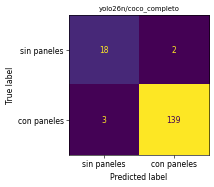

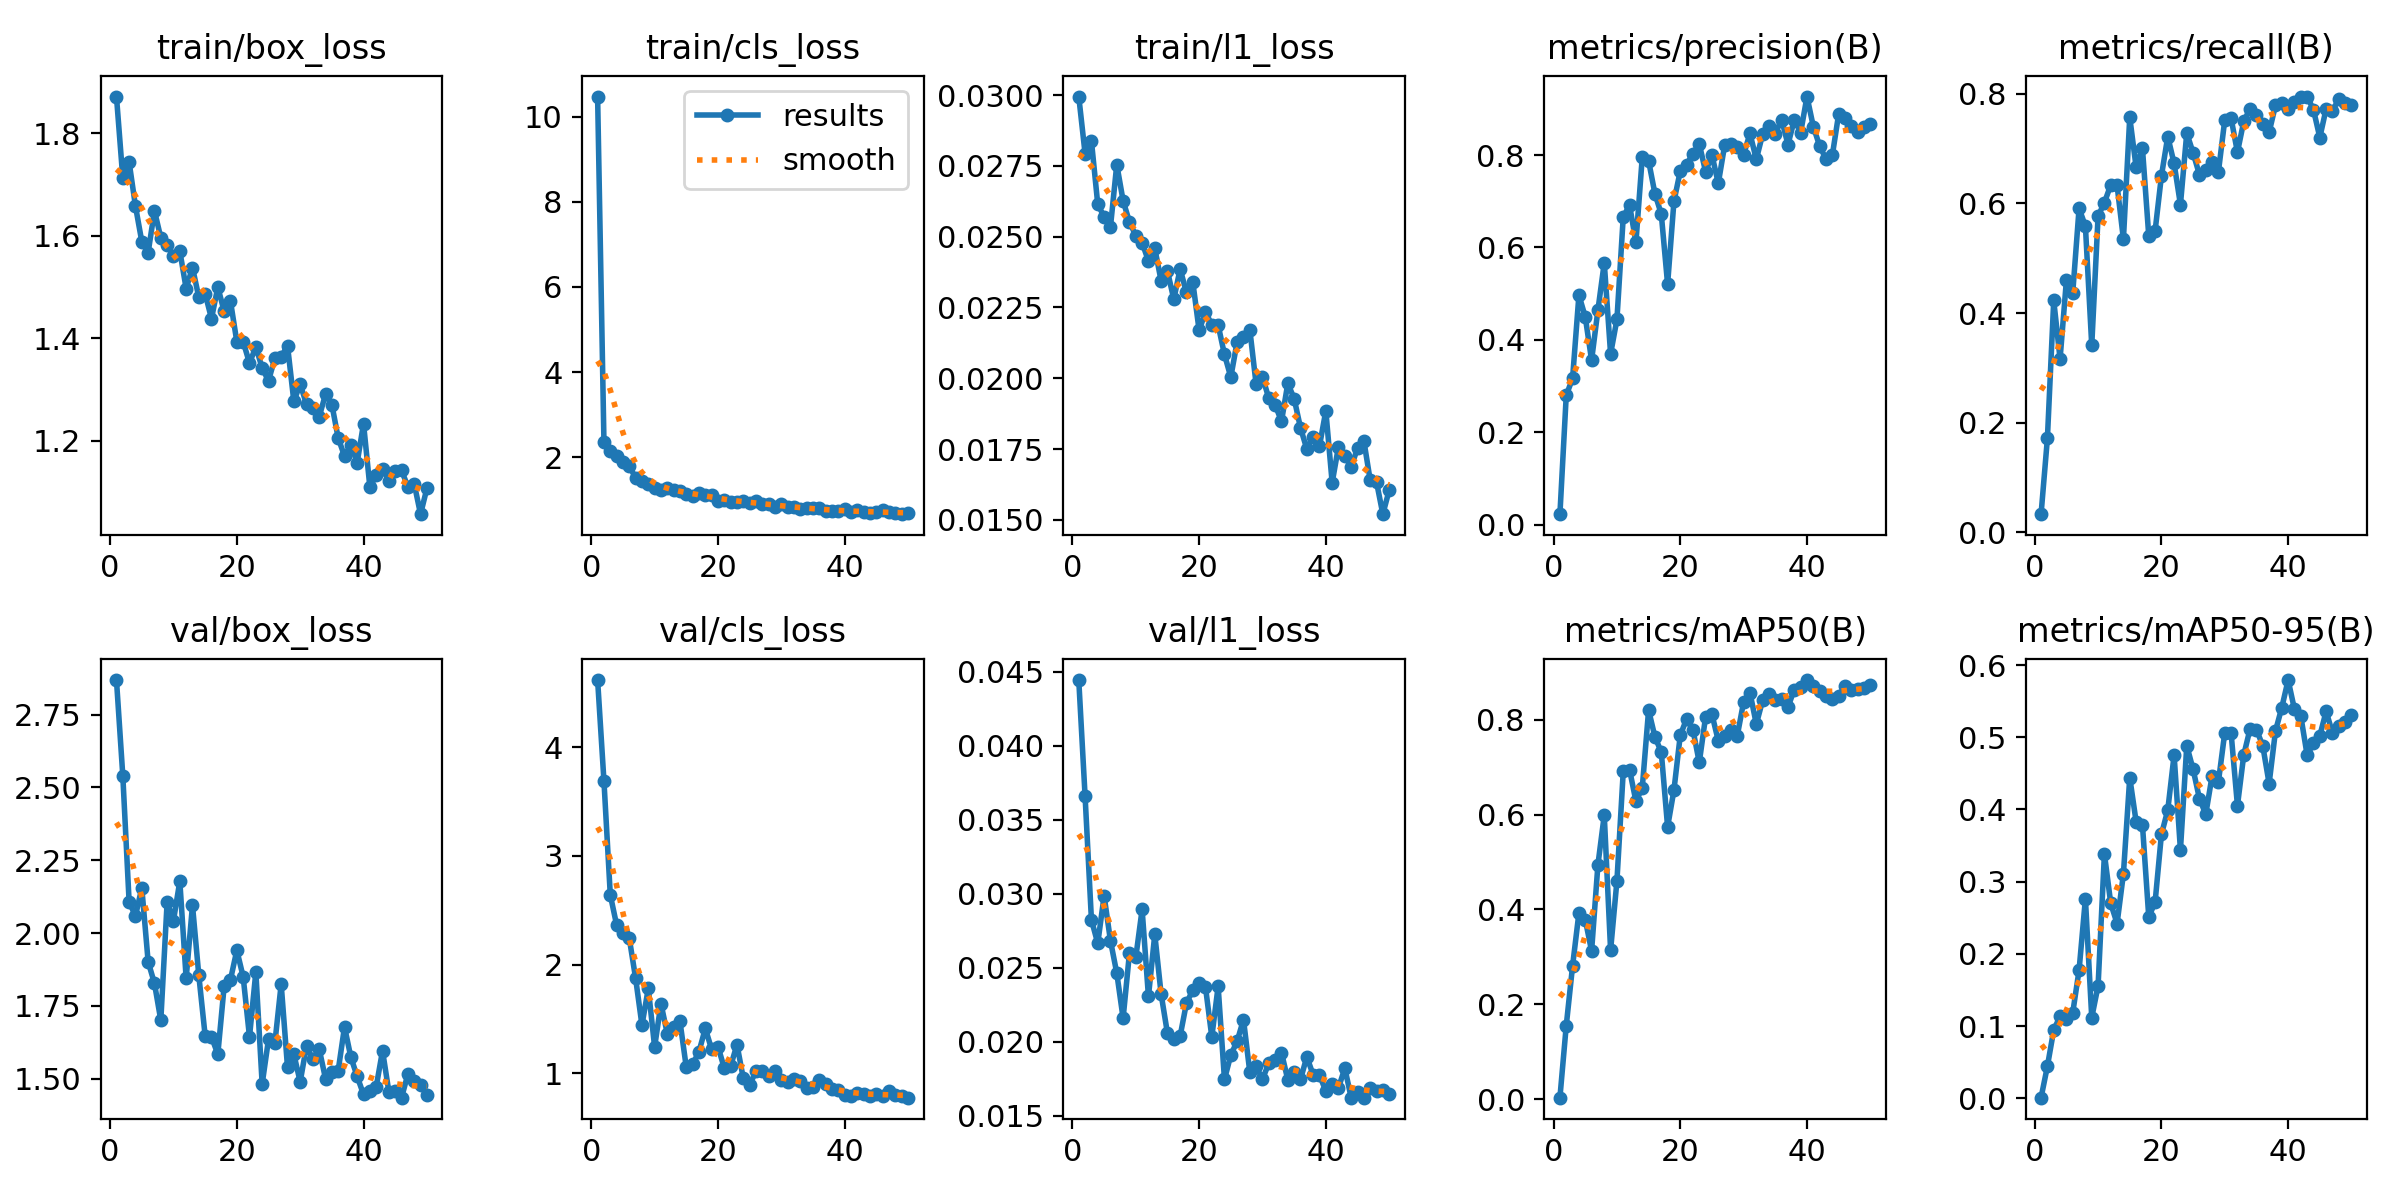

,map50,map50_95,precision,recall
val,0.883087,0.580293,0.926521,0.771556
jamaica,0.755421,0.568610,0.860444,0.714286


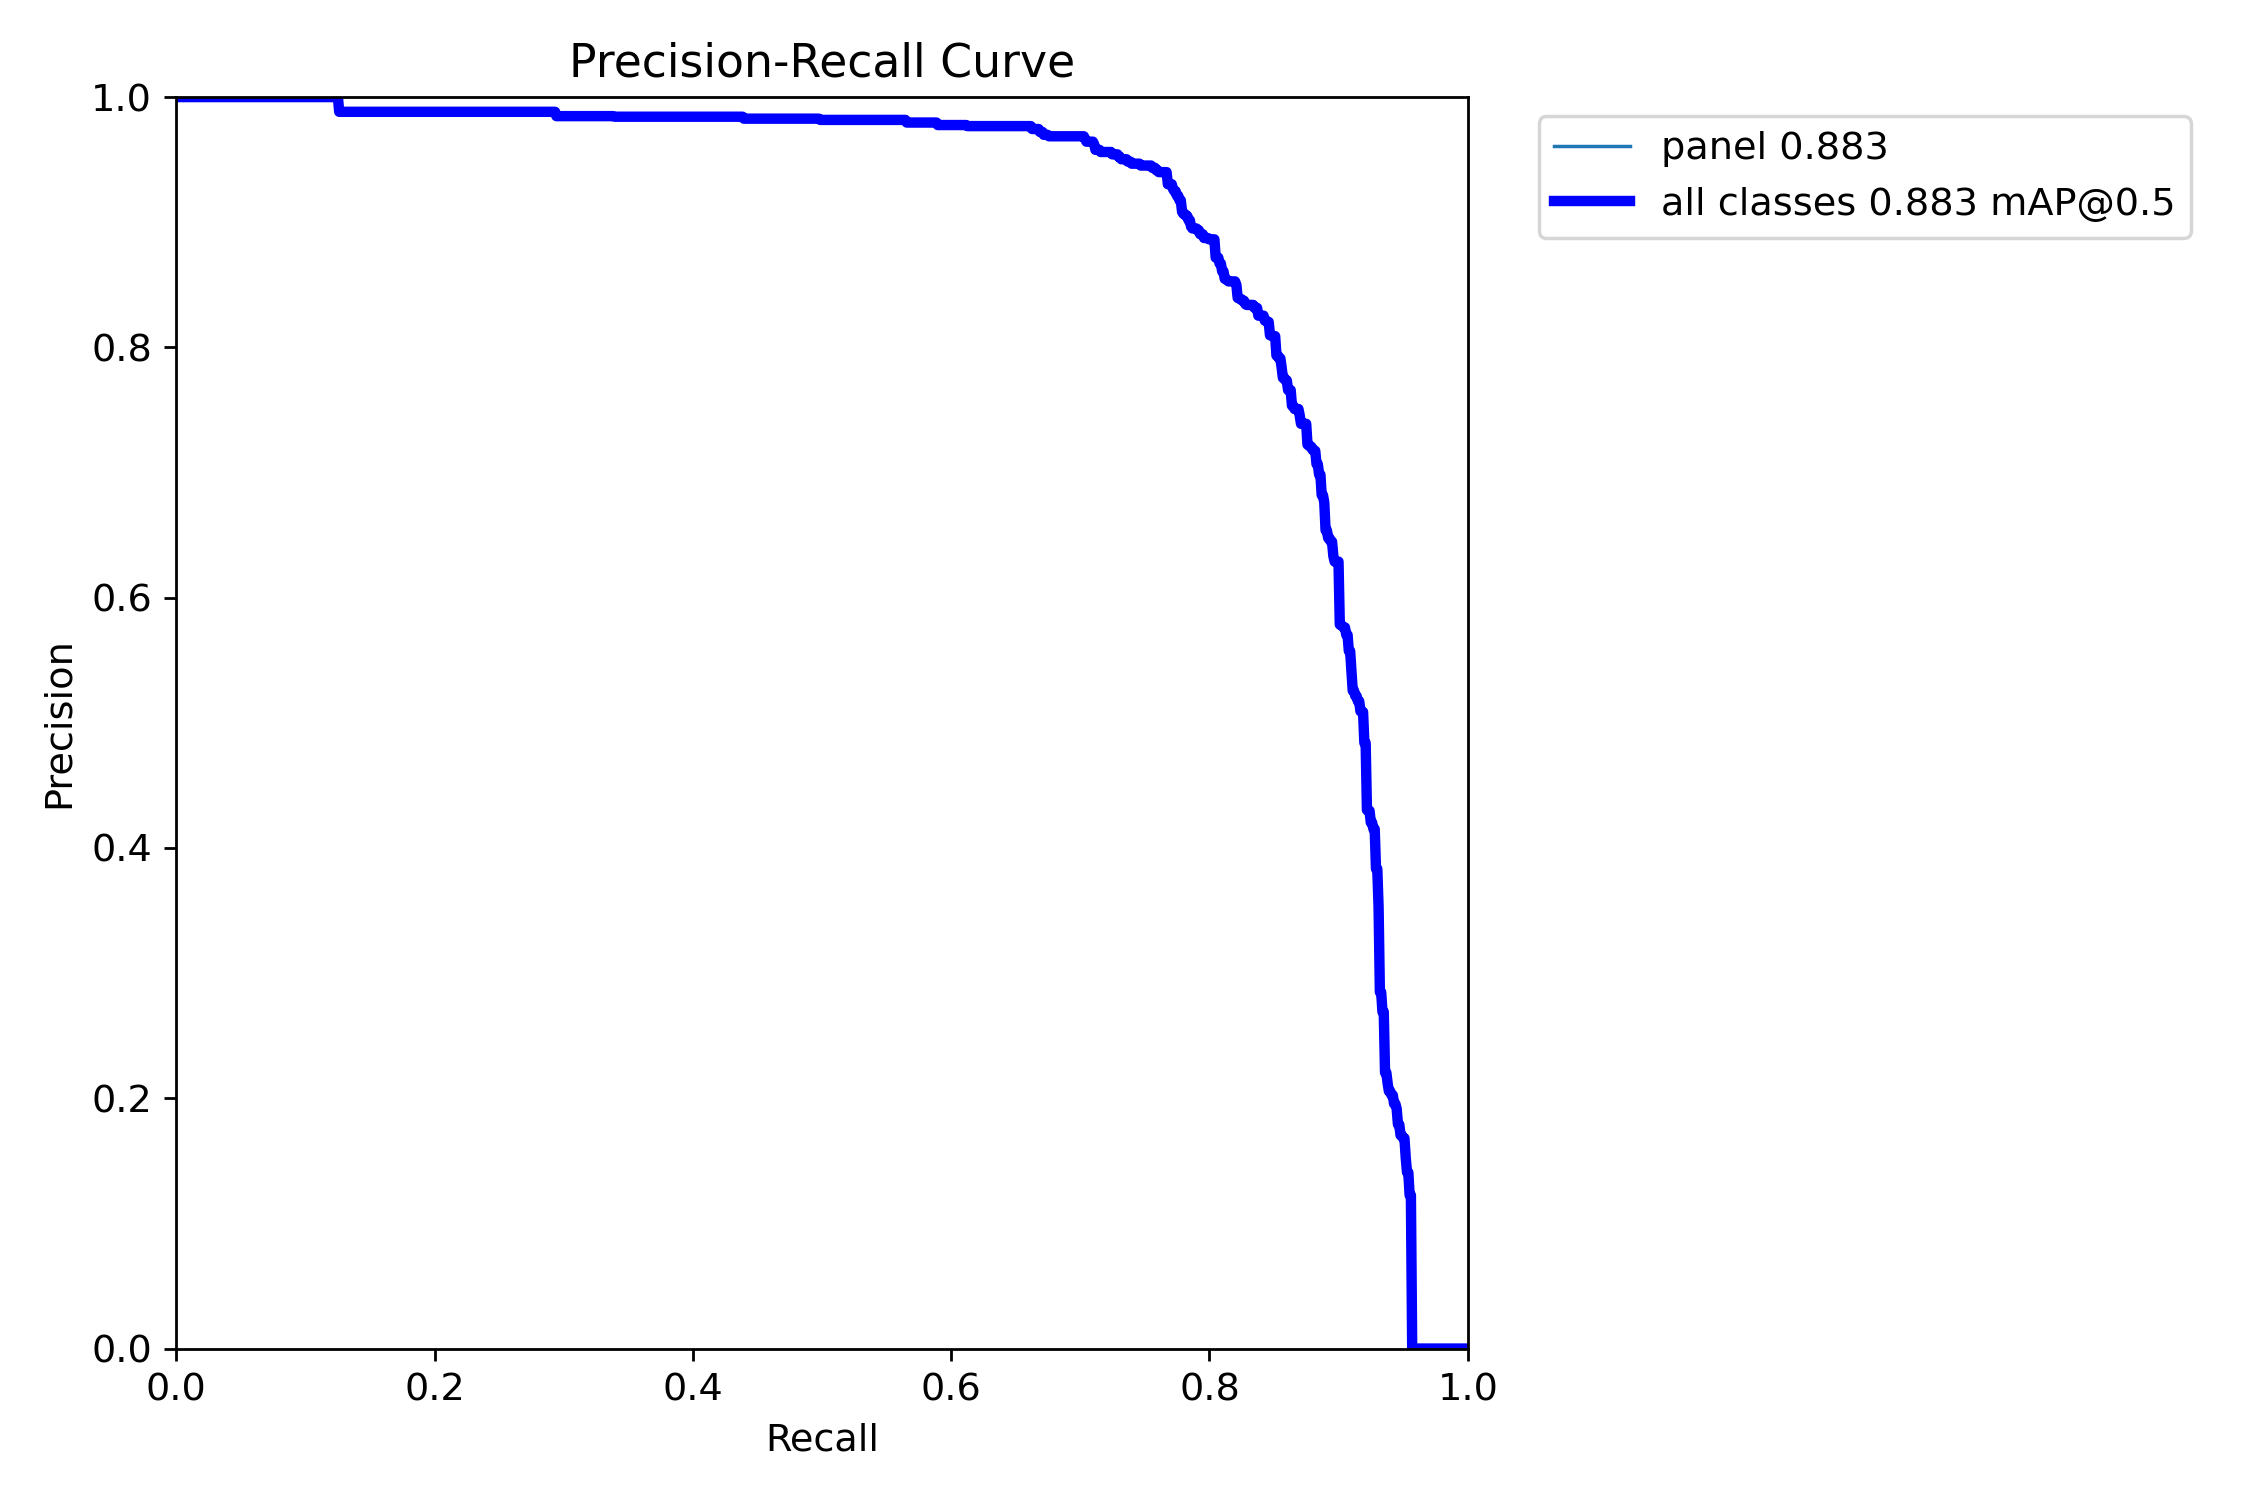


yolo26n/coco_backbone_congelado · fecha original: 2026-11-06T20:37:44 · commit: 17be618c81f79a8788e72751ac82259cc671f78a
SHA-256 de las fuentes consultadas:
config.json 2d6ec6e1de4c9f3b930bbda7220c1a4c01b8a50257e0f1b5f4be653c474ea58a
metricas.json 01746d7b13ce3bba52a7b88d9a57e05dbc109434719c786b0f06f5df67ebeb4b
predicciones_val.csv 4b131fb92ba424ba001b7cf7d3915083ced2d22b501ee045e3a03114bc36e774


,modelo,modo,fecha,commit,sin_pesos,params.arquitectura,params.inicializacion,params.freeze,params.receta.imgsz,params.receta.batch,...,params.entorno.paquetes.ultralytics,params.entorno.paquetes.torch,params.entorno.paquetes.torchvision,params.entorno.paquetes.numpy,params.entorno.paquetes.pandas,params.criterio_datos,params.evaluacion,params.cabeza,params.puntaje_clasificacion,params.umbral_clasificacion
0,yolo26n,coco_backbone_congelado,2026-11-06T20:37:44,17be618c81f79a8788e72751ac82259cc671f78a,False,yolo26n,COCO yolo26n.pt,11,640,16,...,8.4.184,2.14.1+cu130,0.29.1+cu130,2.2.6,2.2.3,v1: clase panel; excluir solo Z01/linea 1; man...,val selecciona checkpoint y reporta; N06/N16 p...,"nms=None: one-to-many con NMS, como YOLOv8n y ...",maxima confianza de cajas tras NMS; 0 sin dete...,0.25


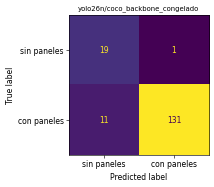

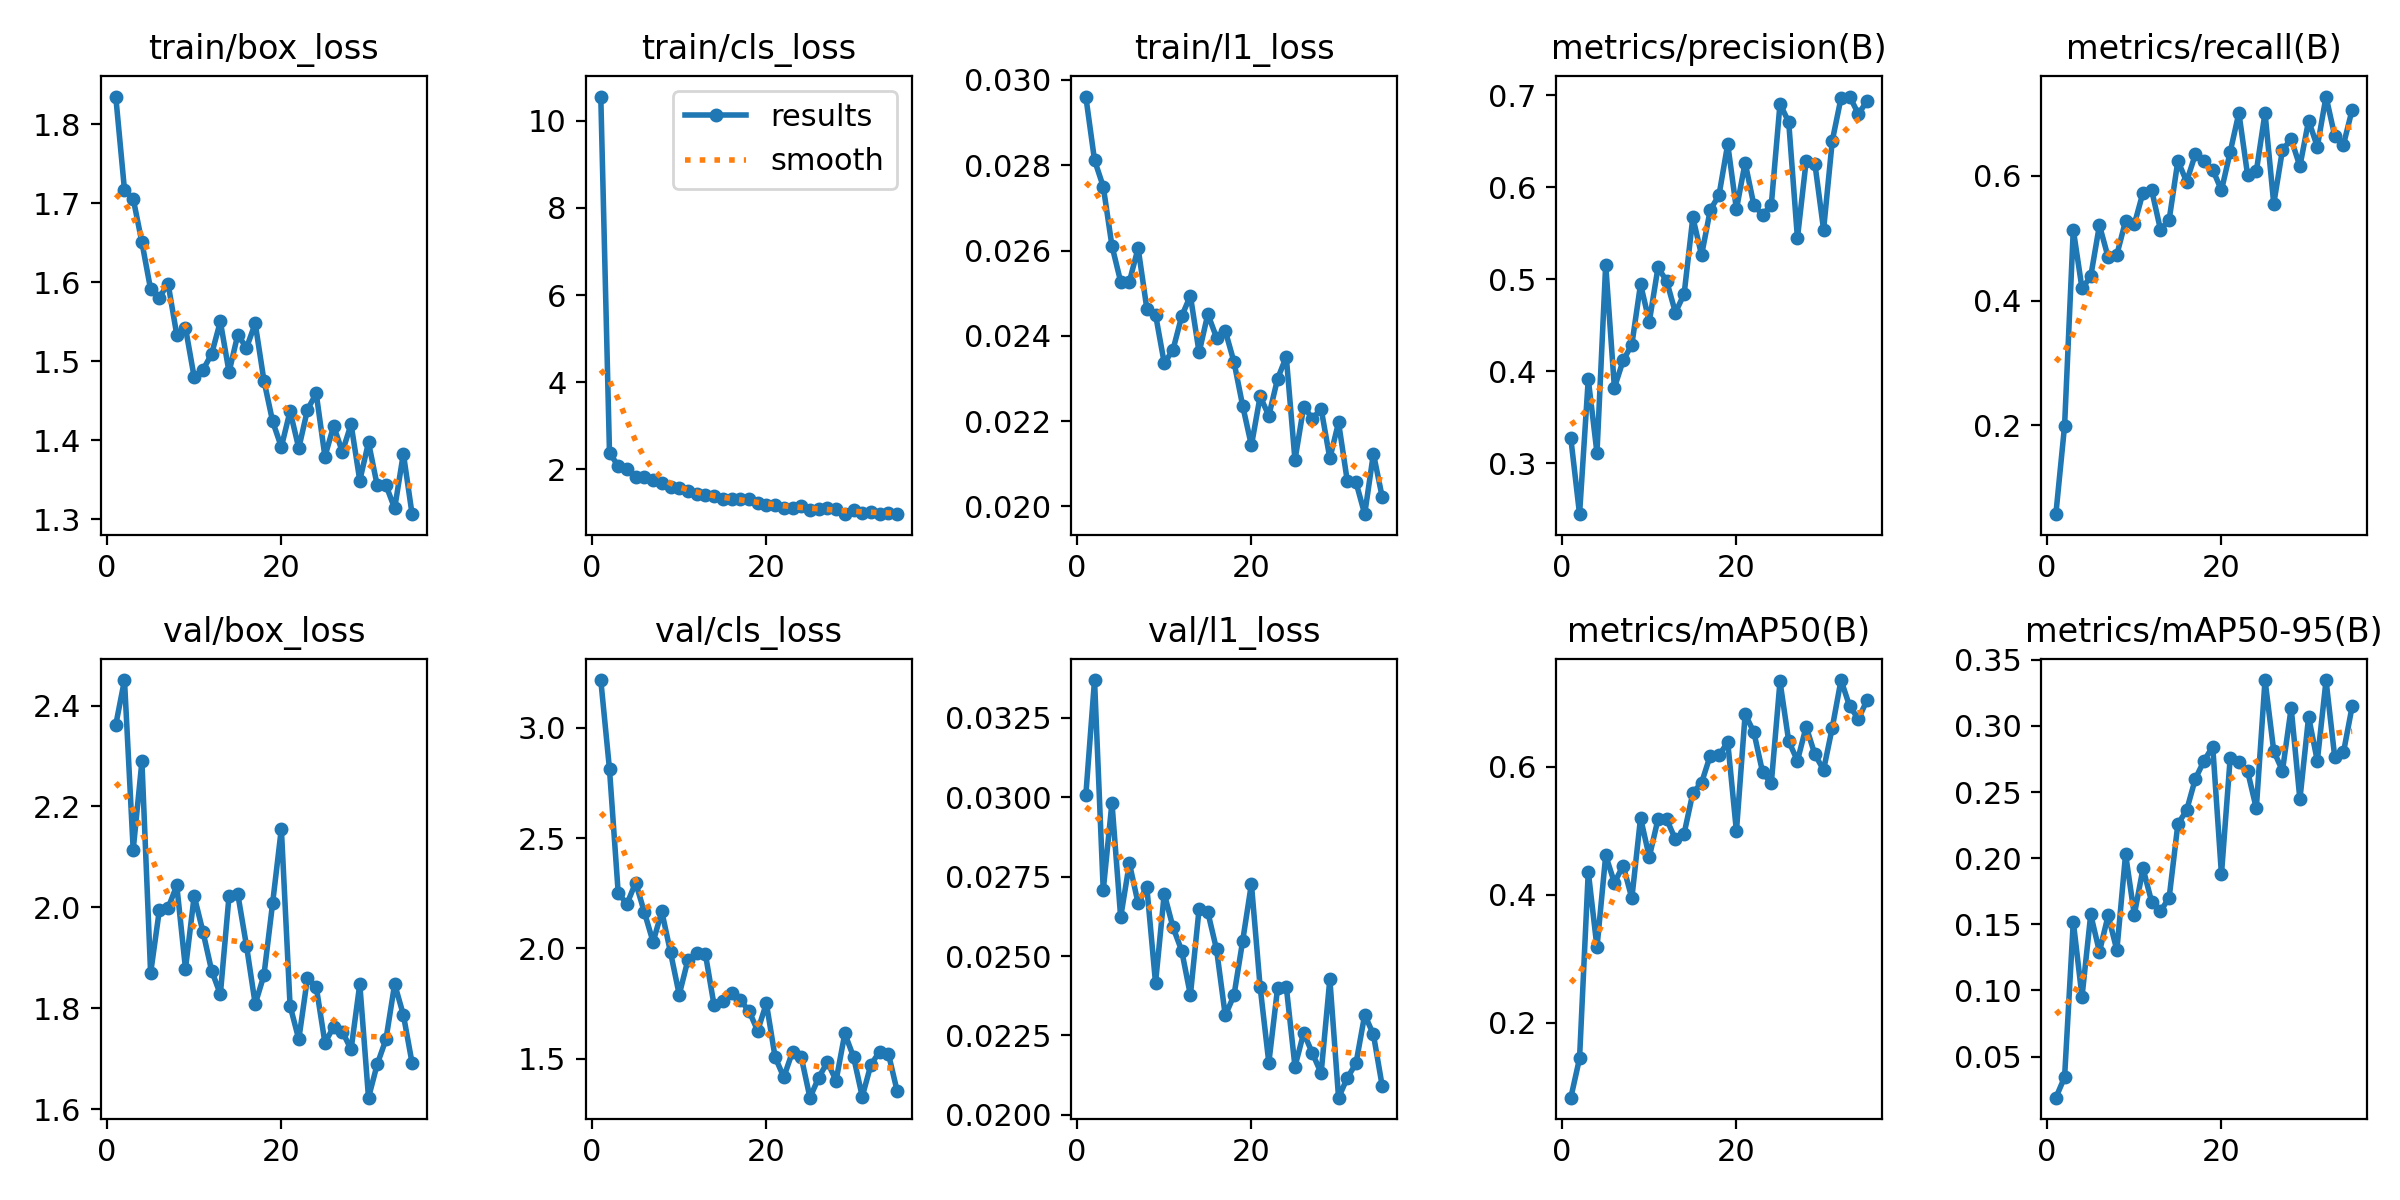

,map50,map50_95,precision,recall
val,0.734008,0.334034,0.694519,0.699301
jamaica,0.421810,0.174402,0.509532,0.428571


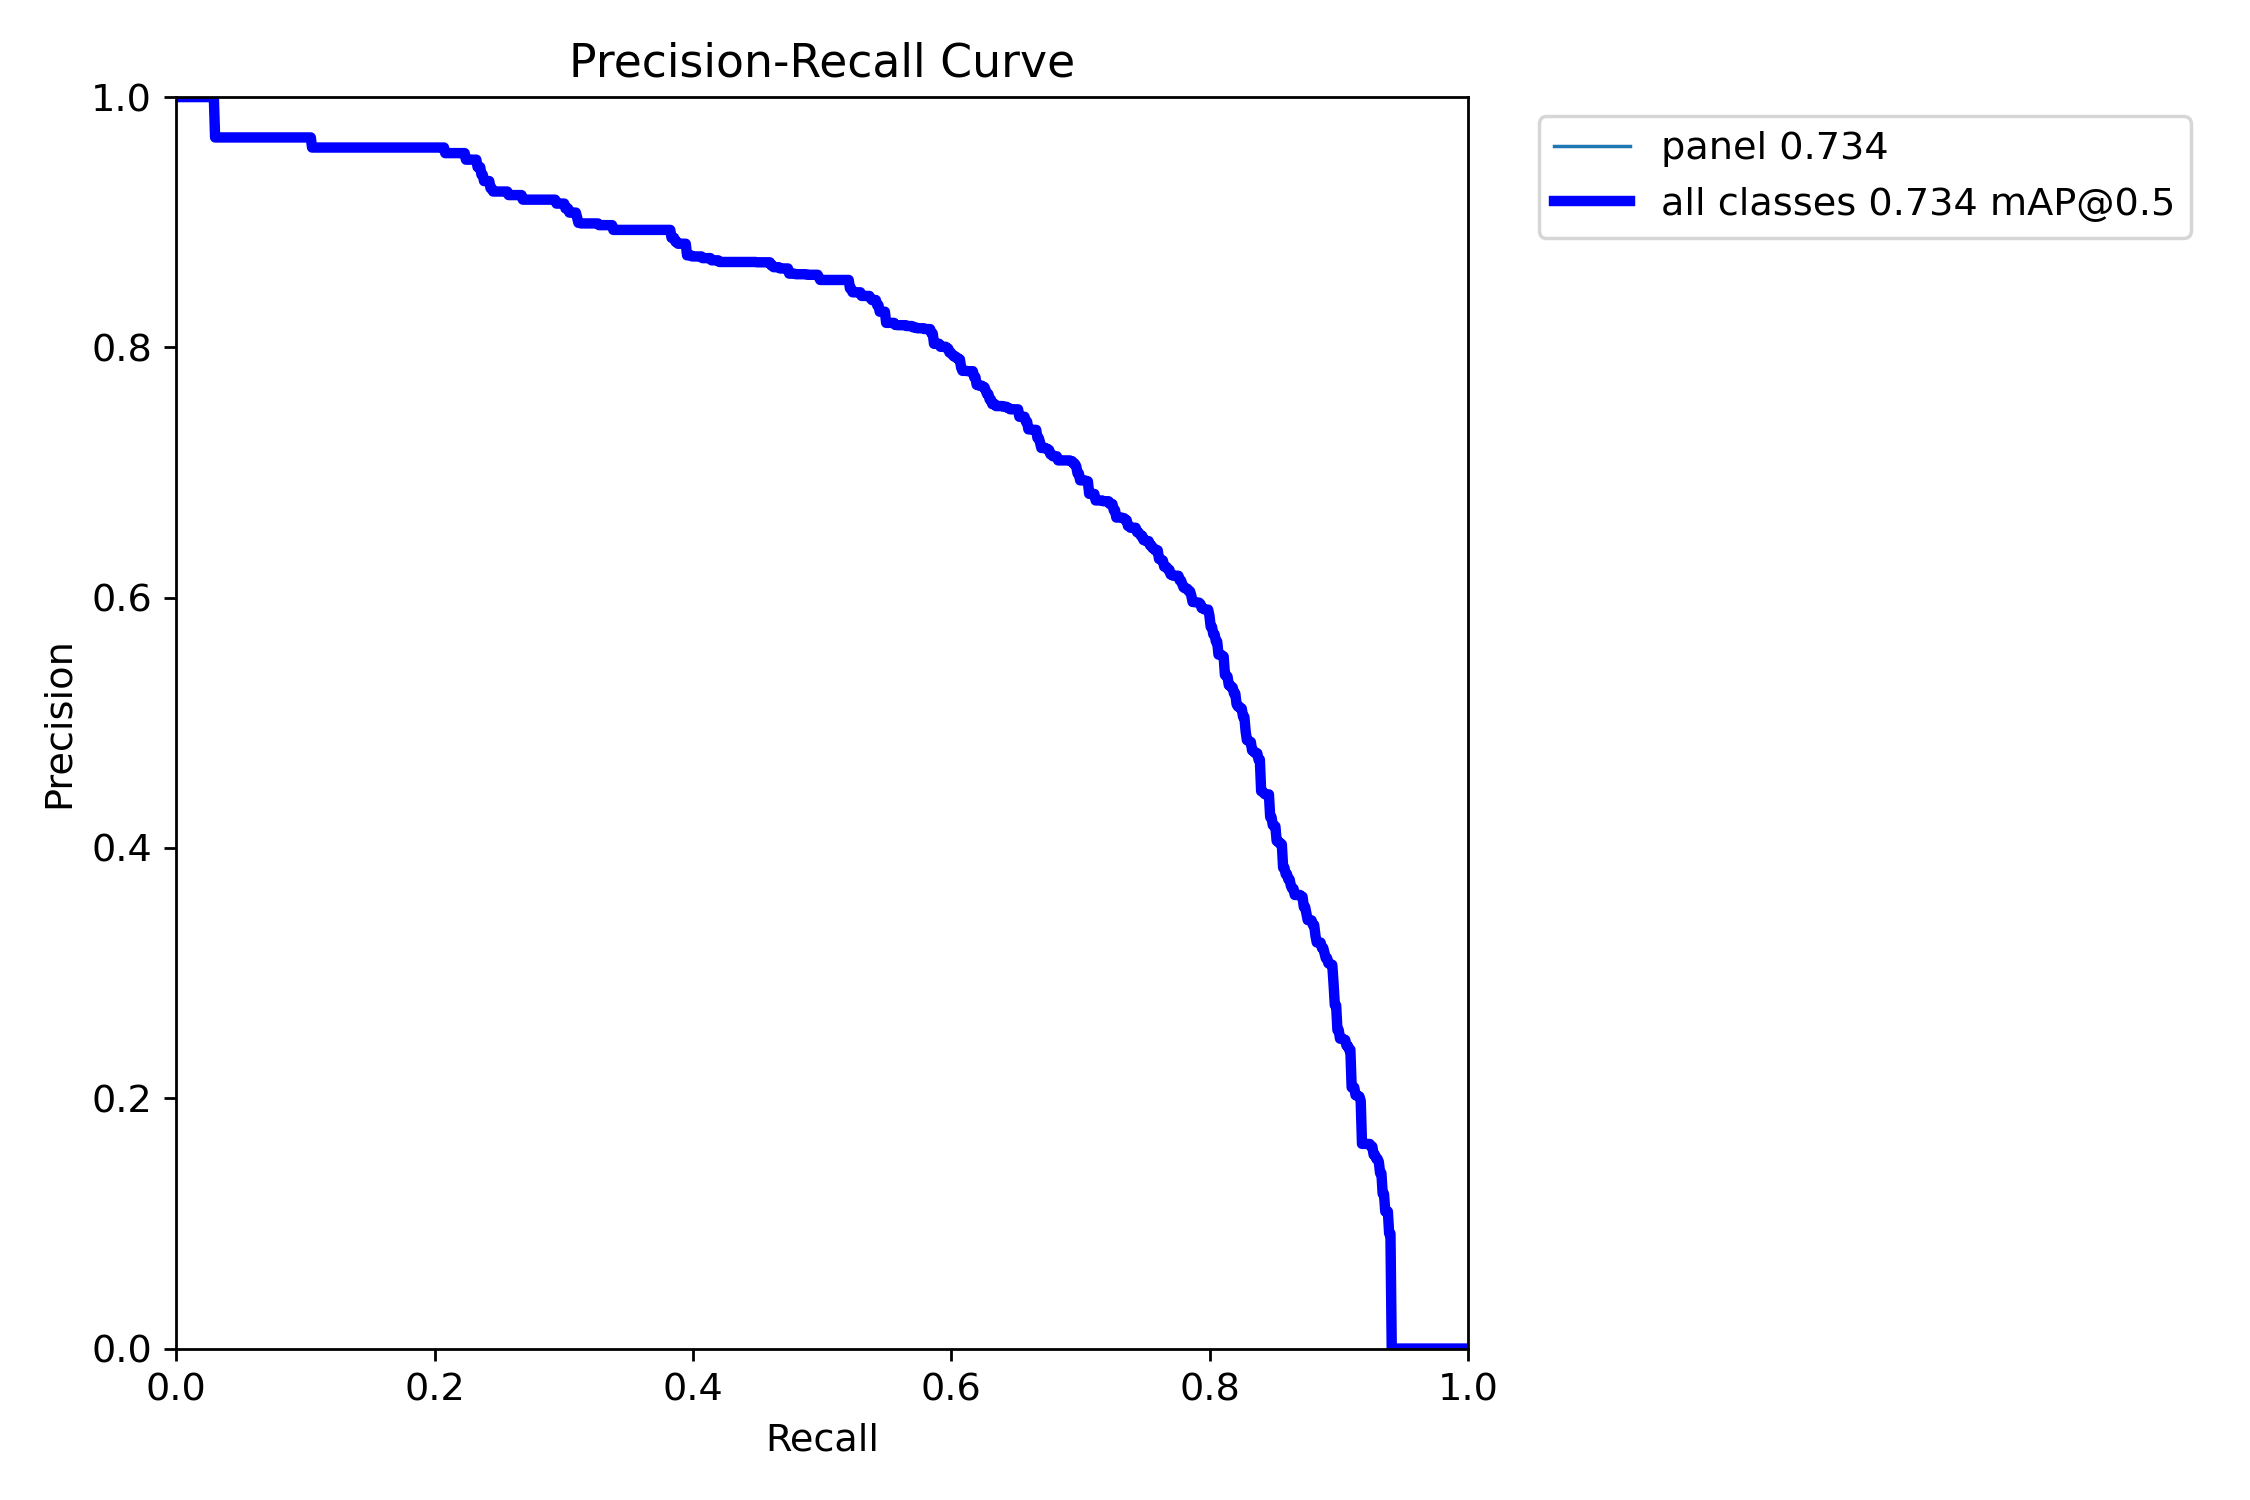

In [1]:
# Consulta independiente: ejecutar solo esta celda para mostrar resultados guardados.
# Las celdas de entrenamiento de arriba no se ejecutan en la copia publicada.
import sys
from pathlib import Path
raiz_consulta = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "pdi_tp" / "lectura_entrega.py").is_file()), None)
if raiz_consulta is None:
    raise FileNotFoundError("Abrí el notebook desde el repositorio clonado.")
sys.path.insert(0, str(raiz_consulta))
from pdi_tp import lectura_entrega
lectura_entrega.mostrar_modelo("yolo26n")
